# Dry Bean Classification: Model Training

This notebook trains and compares the five classifiers required by the assignment using the UCI Dry Bean dataset. It has 13,611 rows, 16 numeric features, and seven bean classes.

- Inspect the feature columns, class balance, and duplicate records.
- Decide on the splitting strategy
- Pick the right model evaluation metrics
- Compare five classifiers using the same split and multiclass metrics.
- Save fitted models and labeled held-out test data for the Streamlit app.

In [1]:
import pandas as pd

dataset_path = "data/dry_bean.csv"
df = pd.read_csv(dataset_path)
TARGET_COLUMN = "Class"
df.to_csv(dataset_path, index=False)

print("CSV output:", dataset_path)
print("Shape:", df.shape)
print("Feature count:", len(df.columns) - 1)
print("Data types:")
print(df.dtypes.value_counts())
print("Class counts:")
print(df[TARGET_COLUMN].value_counts().sort_index())

CSV output: data/dry_bean.csv
Shape: (13611, 17)
Feature count: 16
Data types:
float64    14
int64       2
str         1
Name: count, dtype: int64
Class counts:
Class
BARBUNYA    1322
BOMBAY       522
CALI        1630
DERMASON    3546
HOROZ       1928
SEKER       2027
SIRA        2636
Name: count, dtype: int64


In [2]:
feature_cols = df.columns.drop(TARGET_COLUMN).tolist()
feature_data = df[feature_cols]

# Preprocessing and data inspection
exact_duplicate_rows = int(df.duplicated().sum())
repeated_feature_rows = int(feature_data.duplicated(keep=False).sum())
label_counts = df.groupby(feature_cols, dropna=False)[TARGET_COLUMN].nunique()
conflicting_groups = label_counts[label_counts > 1]

print("Exact duplicate rows beyond first copy:", exact_duplicate_rows)
print("Rows in repeated feature-vector groups:", repeated_feature_rows)
print("Repeated feature-vector groups:", int(feature_data.value_counts(dropna=False).gt(1).sum()))
print("Feature groups with conflicting class labels:", len(conflicting_groups))
print("Class counts:")
print(df[TARGET_COLUMN].value_counts().sort_index())

Exact duplicate rows beyond first copy: 68
Rows in repeated feature-vector groups: 136
Repeated feature-vector groups: 68
Feature groups with conflicting class labels: 0
Class counts:
Class
BARBUNYA    1322
BOMBAY       522
CALI        1630
DERMASON    3546
HOROZ       1928
SEKER       2027
SIRA        2636
Name: count, dtype: int64


Dataset preview:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER



Column types:


,column_count
dtype,
float64,14
int64,2
str,1


Missing values: 0

Class counts:


,count
Class,
BARBUNYA,1322
BOMBAY,522
CALI,1630
DERMASON,3546
HOROZ,1928
SEKER,2027
SIRA,2636


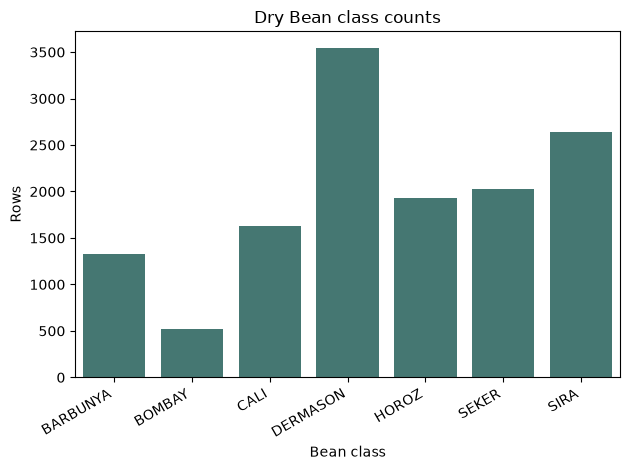

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Explore the dataset before planning the dataset splitting
data = pd.read_csv(dataset_path)
class_names = sorted(data[TARGET_COLUMN].unique())

print("Dataset preview:")
display(data.head())
print("\nColumn types:")
display(data.dtypes.value_counts().rename_axis("dtype").to_frame("column_count"))
print("Missing values:", int(data.isna().sum().sum()))
print("\nClass counts:")
display(data[TARGET_COLUMN].value_counts().sort_index().rename_axis("Class").to_frame("count"))

ax = sns.countplot(data=data, x=TARGET_COLUMN, order=class_names, color="#3d7f78")
ax.set(title="Dry Bean class counts", xlabel="Bean class", ylabel="Rows")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [4]:
from sklearn.model_selection import StratifiedGroupKFold

RANDOM_SEED = 42
data = pd.read_csv(dataset_path)

X = data.drop(columns=TARGET_COLUMN)
y = data[TARGET_COLUMN]
class_names = sorted(y.unique())

# Do a stratified group split to keep repeated feature vectors together and maintain class distribution.
groups = pd.MultiIndex.from_frame(X).factorize()[0]
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
train_indices, test_indices = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_indices], X.iloc[test_indices]
y_train, y_test = y.iloc[train_indices], y.iloc[test_indices]

split_summary = pd.concat(
    [
        y_train.value_counts(normalize=True).rename("train proportion"),
        y_test.value_counts(normalize=True).rename("test proportion"),
    ],
    axis=1,
).sort_index()

train_groups = set(groups[train_indices])
test_groups = set(groups[test_indices])

overlap = train_groups.intersection(test_groups)

print(f"Dataset: {data.shape[0]:,} rows, {X.shape[1]} features")
print(f"Bean classes: {class_names}")
print(f"Train rows: {len(X_train):,}; test rows: {len(X_test):,}")
print(f"Shared feature vectors across splits: {len(overlap)}")
display(split_summary.style.format("{:.3f}"))

Dataset: 13,611 rows, 16 features
Bean classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
Train rows: 10,889; test rows: 2,722
Shared feature vectors across splits: 0


,train proportion,test proportion
Class,,
BARBUNYA,0.097,0.097
BOMBAY,0.038,0.038
CALI,0.120,0.120
DERMASON,0.261,0.260
HOROZ,0.142,0.142
SEKER,0.149,0.149
SIRA,0.194,0.194


## Train and compare models

The notebook uses a **stratified group split**: repeated feature vectors stay in the same partition, preventing exact duplicates from leaking across train and test. Stratification keeps all seven bean classes represented at similar proportions in both splits.

Because this is multiclass classification, precision, recall, and F1 use **macro averaging** (each class contributes equally), and ROC-AUC uses macro one-vs-rest. MCC is calculated with its multiclass definition. The held-out test set is for final comparison, not repeated model tuning.

In [5]:
import numpy as np
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

model_pipelines = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=RANDOM_SEED),
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_SEED),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
"Gaussian Naive Bayes": make_pipeline(
        FunctionTransformer(np.log1p),
        GaussianNB(),
    ),
    "Support Vector Machine": make_pipeline(
        StandardScaler(),
        CalibratedClassifierCV(
            SVC(random_state=RANDOM_SEED),
            ensemble=False,
        ),
    ),
}

# Evaluate each model on the test set and calculate performance metrics
# The metrics calculated include Accuracy, AUC, Precision, Recall, F1, and MCC for each model.
# Using macro f1 for multi-class evaluation
metric_rows = []
for model_name, model in model_pipelines.items():
    model.fit(X_train, y_train)
    predicted_labels = model.predict(X_test)
    class_probabilities = model.predict_proba(X_test)

    metric_rows.append(
        {
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, predicted_labels),
            "AUC": roc_auc_score(
                y_test,
                class_probabilities,
                labels=model.classes_,
                multi_class="ovr",
                average="macro",
            ),
            "Precision": precision_score(
                y_test, predicted_labels, average="macro", zero_division=0
            ),
            "Recall": recall_score(
                y_test, predicted_labels, average="macro", zero_division=0
            ),
            "F1": f1_score(
                y_test, predicted_labels, average="macro", zero_division=0
            ),
            "MCC": matthews_corrcoef(y_test, predicted_labels),
        }
    )

metrics_df = pd.DataFrame(metric_rows).set_index("Model")
display(metrics_df.style.format("{:.4f}"))

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.9273,0.9949,0.9393,0.9365,0.9378,0.9121
Decision Tree,0.8953,0.9447,0.9086,0.9077,0.9081,0.8734
KNN,0.9195,0.9841,0.9324,0.9308,0.9316,0.9027
Gaussian Naive Bayes,0.8942,0.9909,0.9044,0.9023,0.9024,0.8727
Support Vector Machine,0.9298,0.9908,0.9423,0.9388,0.9405,0.9151


Models ranked by macro F1:


,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Support Vector Machine,0.930,0.991,0.942,0.939,0.940,0.915
Logistic Regression,0.927,0.995,0.939,0.936,0.938,0.912
KNN,0.920,0.984,0.932,0.931,0.932,0.903
Decision Tree,0.895,0.945,0.909,0.908,0.908,0.873
Gaussian Naive Bayes,0.894,0.991,0.904,0.902,0.902,0.873



Classification report for the highest-macro-F1 model: Support Vector Machine
              precision    recall  f1-score   support

    BARBUNYA       0.94      0.91      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.95      0.93      0.94       326
    DERMASON       0.93      0.93      0.93       709
       HOROZ       0.96      0.96      0.96       386
       SEKER       0.96      0.96      0.96       405
        SIRA       0.86      0.89      0.87       527

    accuracy                           0.93      2722
   macro avg       0.94      0.94      0.94      2722
weighted avg       0.93      0.93      0.93      2722



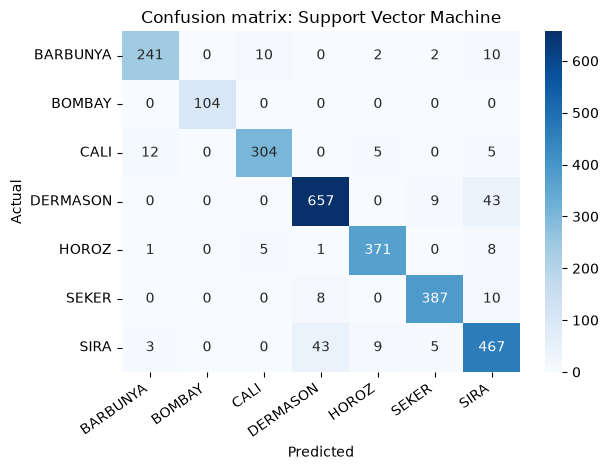

In [6]:
from sklearn.metrics import classification_report, confusion_matrix

metrics_df = metrics_df.sort_values("F1", ascending=False)
print("Models ranked by macro F1:")
display(metrics_df.style.format("{:.3f}"))

best_model_name = metrics_df.index[0]
best_model = model_pipelines[best_model_name]
best_predictions = best_model.predict(X_test)

print(f"\nClassification report for the highest-macro-F1 model: {best_model_name}")
print(
    classification_report(
        y_test,
        best_predictions,
        labels=class_names,
        target_names=class_names,
        zero_division=0,
    )
)

matrix = confusion_matrix(y_test, best_predictions, labels=class_names)
ax = sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
)
ax.set(title=f"Confusion matrix: {best_model_name}", xlabel="Predicted", ylabel="Actual")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
import joblib

# Save trained models and evaluation data to disk
for model_name, model in model_pipelines.items():
    filename = "".join(
        character.lower() if character.isalnum() else "_"
        for character in model_name
    ).strip("_")
    model_path = f"{filename}.joblib"
    joblib.dump(model, model_path)
    print(f"Saved {model_name}: {model_path}")

# Preserve the original seven-class target for evaluation in the app.
test_data = X_test.copy()
test_data[TARGET_COLUMN] = y_test
test_data_path = "test_data.csv"
test_data.to_csv(test_data_path, index=False)

print(f"\nSaved labeled test data: {test_data_path}")

Saved Logistic Regression: logistic_regression.joblib
Saved Decision Tree: decision_tree.joblib
Saved KNN: knn.joblib
Saved Gaussian Naive Bayes: gaussian_naive_bayes.joblib
Saved Support Vector Machine: support_vector_machine.joblib

Saved labeled test data: test_data.csv
